# 08 · Clustering: Suspicious Ads, Car Segments and Make Groups

**Goal:** use the unsupervised lessons (module 04: K-Means, DBSCAN, agglomerative clustering) for three jobs the
supervised models cannot do on their own:

1. **DBSCAN: find suspicious ads.** Listings that sit in low-density areas (noise, label −1) are the unusual ones:
   typos, placeholder prices, damaged cars. This tests the odometer-typo problem found in notebook 06.
2. **K-Means: describe car segments.** A handful of car types a seller or buyer recognises, used to show where the
   pricing tool works well and where it does not.
3. **Agglomerative clustering: group the car makes** by their profile, with a dendrogram.

Clustering learns from the data, so every clustering model here is **fit on the training set only**; the test set
is only labelled with the fitted models. Following the lessons, features are **standard-scaled** before every
clustering, and the silhouette score and inertia are used to compare settings.

⏱️ *Runtime: about 5 minutes, mostly four Random Forest fits (sections 1 and 4).*

In [1]:
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score

sys.path.append('../src')
from prep import load_data, split, add_model_top, RANDOM_STATE

sns.set_theme(style='whitegrid')
df = load_data()
X_train, X_test, y_train, y_test = split(df)
X_train, X_test = add_model_top(X_train, X_test)
train = X_train.assign(price=y_train.values)
test = X_test.assign(price=y_test.values).reset_index(drop=True)

preds = pd.read_csv('../results/test_predictions.csv')       # notebook 05, same row order as y_test
assert (preds['price'].values == y_test.values).all()
test['rf_pred'] = preds['Random Forest'].values
price_range = json.load(open('../results/price_range.json'))  # notebook 07
print(f'training cars: {len(train):,} | test cars: {len(test):,}')

training cars: 166,115 | test cars: 41,529


## 1. DBSCAN: which ads look suspicious?

**Features:** car age, mileage (log) and asking price (log). Price is allowed here because this is a data check,
not a prediction: the question is *"does this combination of age, mileage and price look like other ads?"*.
Mileage and price are logged first because both are right-skewed (notebook 02).

DBSCAN compares every car with its neighbours, so memory grows quickly with the number of rows. As in the
lesson's manual grid search, it is run on a **random sample of 30,000 training cars**.

In [2]:
sample = train.dropna(subset=['odometer']).sample(30_000, random_state=RANDOM_STATE)
F = pd.DataFrame({'car_age': sample['car_age'],
                  'log_miles': np.log1p(sample['odometer']),
                  'log_price': np.log(sample['price'])})
F_scaled = StandardScaler().fit_transform(F)

# Manual grid search, as in the lesson: noise (-1) is not counted as a cluster
rows = []
t = time.time()
for eps in [0.15, 0.2, 0.25, 0.3, 0.35]:
    for min_samples in [5, 10, 20]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(F_scaled)
        n_clusters = len(set(labels) - {-1})
        sil = silhouette_score(F_scaled, labels, sample_size=10_000, random_state=RANDOM_STATE) \
              if n_clusters >= 2 else np.nan
        rows.append({'eps': eps, 'min_samples': min_samples, 'n_clusters': n_clusters,
                     'noise_%': (labels == -1).mean() * 100, 'silhouette': sil})
grid = pd.DataFrame(rows).round(3)
print(f'grid search: {time.time() - t:.0f} s')
grid

grid search: 19 s


,eps,min_samples,n_clusters,noise_%,silhouette
0,0.15,5,106,10.223,-0.247
1,0.15,10,48,16.853,-0.232
2,0.15,20,30,27.847,-0.261
3,0.20,5,28,4.417,-0.196
4,0.20,10,7,7.347,-0.045
5,0.20,20,2,11.653,0.274
6,0.25,5,23,2.723,-0.084
7,0.25,10,6,4.447,0.134
8,0.25,20,1,7.063,NaN
9,0.30,5,13,1.907,0.313


**Choosing the setting.** The silhouette score is not much help here: DBSCAN finds one big dense blob (most cars)
plus a few small groups, so the score mostly rewards settings with very few clusters. What matters for a data check
is **how many ads it sets aside as noise**: too many and ordinary cars get flagged, too few and the odd ones are
missed. The lab kept settings with at most 15% noise; for a check that a person would review, a stricter limit of
about **5%** is used here, and among those settings the one with the most noise is kept.

In [3]:
pick = grid[(grid['noise_%'] <= 5) & (grid['n_clusters'] >= 1)].sort_values('noise_%', ascending=False).iloc[0]
print(pick.to_dict())
db = DBSCAN(eps=pick['eps'], min_samples=int(pick['min_samples'])).fit(F_scaled)
sample['dbscan'] = db.labels_
sample['noise'] = db.labels_ == -1
print(f"noise ads: {sample['noise'].sum():,} of {len(sample):,} ({sample['noise'].mean():.1%})")

{'eps': 0.3, 'min_samples': 20.0, 'n_clusters': 1.0, 'noise_%': 4.963, 'silhouette': nan}


noise ads: 1,489 of 30,000 (5.0%)


In [4]:
# What do the noise ads have in common?
checks = sample.assign(
    odometer_typo=(sample['odometer'] <= 1_000) & (sample['car_age'] >= 8),
    price_under_2k=sample['price'] < 2_000,
    price_over_60k=sample['price'] > 60_000,
    branded_title=sample['title_status'].isin(['salvage', 'rebuilt', 'parts only', 'missing']),
    older_than_25=sample['car_age'] > 25,
)
cols = ['odometer_typo', 'price_under_2k', 'price_over_60k', 'branded_title', 'older_than_25']
profile = (checks.groupby('noise')[cols].mean() * 100).round(1)
profile.index = ['clustered ads', 'noise ads']
profile['median price'] = checks.groupby('noise')['price'].median().values
profile['median miles'] = checks.groupby('noise')['odometer'].median().values
profile

,odometer_typo,price_under_2k,price_over_60k,branded_title,older_than_25,median price,median miles
clustered ads,0.0,1.8,1.0,4.1,0.7,11900.0,107308.0
noise ads,12.5,14.4,8.6,5.0,21.0,10999.0,31000.0


In [5]:
# Share of each kind of odd ad that DBSCAN catches
caught = pd.Series({c: checks.loc[checks[c], 'noise'].mean() * 100 for c in cols}).round(1)
counts = pd.Series({c: int(checks[c].sum()) for c in cols})
pd.DataFrame({'ads in sample': counts, 'caught as noise (%)': caught})

,ads in sample,caught as noise (%)
odometer_typo,186,100.0
price_under_2k,718,29.9
price_over_60k,403,31.8
branded_title,1245,6.0
older_than_25,499,62.7


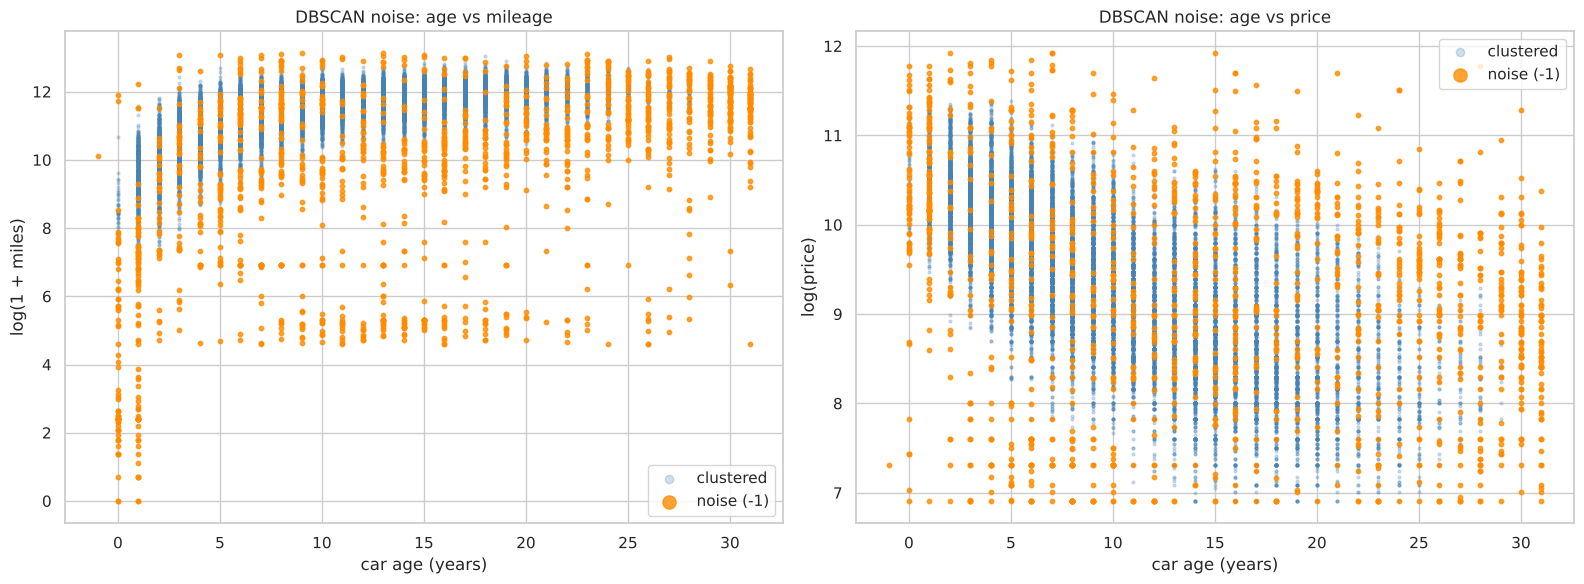

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (x, y) in zip(axes, [('car_age', 'log_miles'), ('car_age', 'log_price')]):
    ax.scatter(F.loc[~sample['noise'].values, x], F.loc[~sample['noise'].values, y], s=4, alpha=0.25,
               color='steelblue', label='clustered')
    ax.scatter(F.loc[sample['noise'].values, x], F.loc[sample['noise'].values, y], s=10, alpha=0.8,
               color='darkorange', label='noise (-1)')
    ax.set_xlabel('car age (years)')
    ax.set_ylabel({'log_miles': 'log(1 + miles)', 'log_price': 'log(price)'}[y])
    ax.legend(markerscale=3)
axes[0].set_title('DBSCAN noise: age vs mileage')
axes[1].set_title('DBSCAN noise: age vs price')
plt.tight_layout()
plt.show()

**What DBSCAN sets aside:**

- The chosen setting (`eps=0.3`, `min_samples=20`) finds **one large cluster, the normal market, plus 1,489 noise
  ads (5.0% of the sample)**. For spotting odd ads that is exactly what is wanted.
- It catches **every one of the 186 odometer-typo cars** (1,000 miles or less at 8+ years old), **63% of the cars
  older than 25 years** (collector territory, few listings) and about **30% of the prices under \$2,000 or over
  \$60,000**.
- It catches only 6% of salvage or rebuilt titles: a branded title does not make age, mileage and price unusual.
- In the plots, the orange bands at log(miles) of about 5 and 7 are readings of about 150 and 1,000 miles on cars of
  every age, the typo pattern from notebook 06. The bottom row at log(price) of about 6.9 is the \$1,000 price floor,
  where placeholder prices pile up.
- Noise ads have a median of 31,000 miles against 107,308 for clustered ads: low readings dominate them.

### From DBSCAN to a fixed rule

DBSCAN has no `predict`: it can only label the rows it was fit on, and a new ad would need the whole model refit.
So it is used here as **evidence**, and the pattern it finds is turned into a **fixed rule** that learns nothing
from the data and can be applied to every row before the split (like the other rules in `src/clean.py`).

The test below fits the tuned Random Forest twice on the full training set, without and with the rule
*"an odometer of 1,000 miles or less on a car 8 or more years old is a typo → missing"*, and scores both on the
same test cars.

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from prep import tree_preprocessor

best = json.load(open('../results/best_params.json'))['Random Forest']
rf_params = {k.split('__')[1]: v for k, v in best.items()}

def rf_predict(Xtr, ytr, Xte, extra_cats=()):
    # Fit the tuned Random Forest and return its test predictions in dollars. The fitted forest is
    # deleted straight away: with one-car leaves it holds over a gigabyte, and four at once do not fit in memory.
    import gc
    import prep
    pre = prep.tree_preprocessor()
    if extra_cats:   # add extra categorical columns to the one-hot step
        name, pipe, cols = pre.transformers[1]
        pre.transformers[1] = (name, pipe, list(cols) + list(extra_cats))
    rf = make_pipeline(pre, RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE,
                                                  n_jobs=-1, **rf_params))
    rf.fit(Xtr, np.log(ytr))
    pred = np.exp(rf.predict(Xte))
    del rf
    gc.collect()
    return pred

def scores(name, y_true, y_pred):
    err = np.abs(y_pred - y_true)
    cheap = y_true < 5_000
    return {'model': name, 'MAE': err.mean(), 'MAE under $5k': err[cheap].mean(),
            'median % error': np.median(err / y_true) * 100}

typo = lambda X: (X['odometer'] <= 1_000) & (X['car_age'] >= 8)
print(f'training cars hit by the rule: {typo(X_train).sum():,} | test cars: {typo(X_test).sum():,}')

X_train_rule, X_test_rule = X_train.copy(), X_test.copy()
X_train_rule.loc[typo(X_train_rule), 'odometer'] = np.nan
X_test_rule.loc[typo(X_test_rule), 'odometer'] = np.nan

t = time.time()
p_base = rf_predict(X_train, y_train, X_test)
p_rule = rf_predict(X_train_rule, y_train, X_test_rule)
print(f'two fits: {time.time() - t:.0f} s')
rule_table = pd.DataFrame([scores('Random Forest (as before)', y_test.values, p_base),
                           scores('Random Forest + odometer rule', y_test.values, p_rule)]).set_index('model').round(1)
hit = typo(X_test).values
rule_table['MAE on the rule\'s test cars'] = [np.abs(p - y_test.values)[hit].mean().round(0) for p in (p_base, p_rule)]
rule_table

training cars hit by the rule: 913 | test cars: 239


two fits: 131 s


,MAE,MAE under $5k,median % error,MAE on the rule's test cars
model,,,,
Random Forest (as before),3231.4,1785.9,15.8,3190.0
Random Forest + odometer rule,3231.4,1782.2,15.6,3233.0


**The rule does not improve the model:**

- It changes 913 training cars and 239 test cars.
- Overall MAE stays at **\$3,231**. The error on cars under \$5,000 moves by \$4, and the median % error from 15.8%
  to 15.6%.
- On the 239 test cars it changes, the error gets *worse* (\$3,190 → \$3,233). Replacing the typo with the median
  mileage throws away a signal: in this data an old car showing almost no miles really is listed cheaply (median
  \$5,499, notebook 06), and the forest had already learned that from its age.

**Decision:** the rule is **not** added to `src/clean.py`, and the models from notebooks 04–07 stay as they are.
The finding is still useful for the pricing tool: these ads should be **flagged and sent back to the seller**, like
the deal flags in notebook 07, rather than silently changed.

## 2. K-Means: car segments

**Features:** car age, mileage and number of cylinders (missing values filled with the training median), scaled.
Price is **left out**, so the segments describe the car, not its price, and can be used for any new ad.
K-Means is fast, so it is fit on all training cars. The silhouette score compares every pair of cars, so it is
computed on a sample of 10,000.

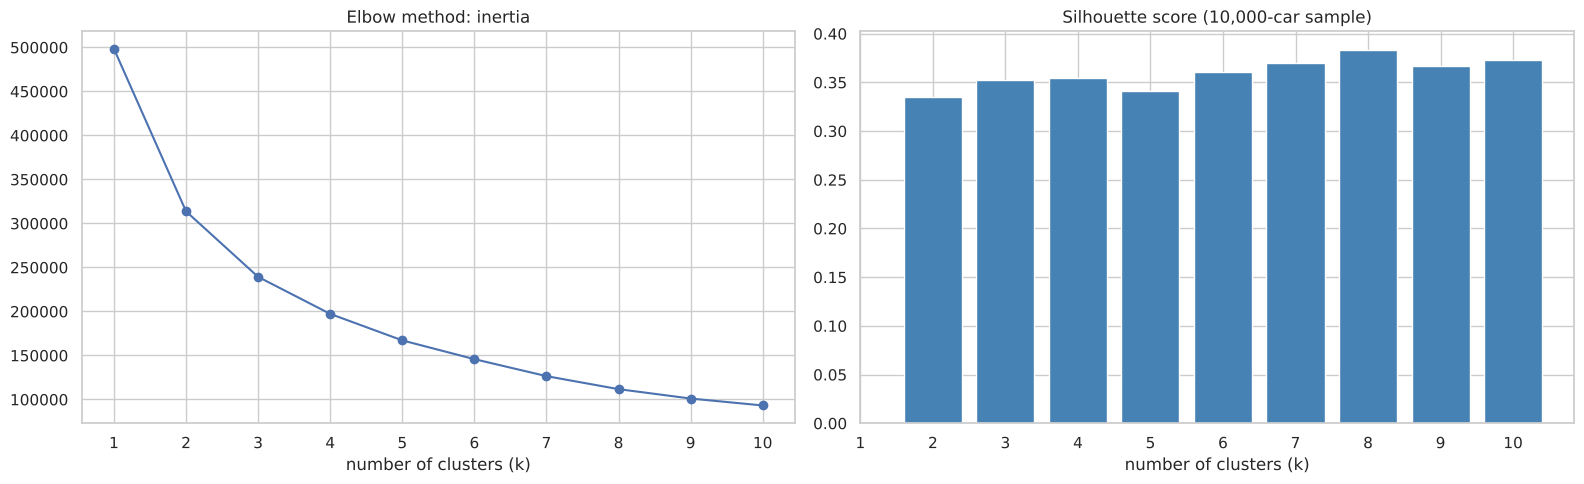

k,1,2,3,4,5,6,7,8,9,10
inertia,498345.0,313731.000,239268.000,197232.000,167112.000,145797.000,126505.00,111722.000,101055.000,93183.000
silhouette,NaN,0.335,0.353,0.354,0.341,0.361,0.37,0.384,0.367,0.373


In [8]:
seg_cols = ['car_age', 'odometer', 'cylinders_num']
seg_median = X_train[seg_cols].median()
seg_scaler = StandardScaler().fit(X_train[seg_cols].fillna(seg_median))
Z_train = seg_scaler.transform(X_train[seg_cols].fillna(seg_median))
idx = np.random.RandomState(RANDOM_STATE).choice(len(Z_train), 10_000, replace=False)

inertias, sils = [], []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(Z_train)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Z_train[idx], km.labels_[idx]) if k > 1 else np.nan)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(range(1, 11), inertias, marker='o')
axes[0].set_title('Elbow method: inertia')
axes[1].bar(range(2, 11), sils[1:], color='steelblue')
axes[1].set_title('Silhouette score (10,000-car sample)')
for ax in axes:
    ax.set_xlabel('number of clusters (k)')
    ax.set_xticks(range(1, 11))
plt.tight_layout()
plt.show()
pd.DataFrame({'k': range(1, 11), 'inertia': np.round(inertias), 'silhouette': np.round(sils, 3)}).set_index('k').T

**No clear elbow.** Inertia falls smoothly and the silhouette score stays between 0.33 and 0.38 for every k (highest:
0.384 at k = 8). Cars spread continuously in age, mileage and engine size, without sharply separated groups.

With no natural k, the lessons say to use business sense: **k = 4** (silhouette 0.354, the same as k = 3 and better
than k = 5) gives four segments a person can name and use. k = 8 is only 0.03 higher but twice as many groups.

In [9]:
K = 4
kmeans = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10).fit(Z_train)
train['segment'] = kmeans.labels_
centroids = pd.DataFrame(seg_scaler.inverse_transform(kmeans.cluster_centers_), columns=seg_cols).round(1)
centroids['cars'] = np.bincount(kmeans.labels_)
centroids['median price'] = train.groupby('segment')['price'].median()
centroids['pickup / truck %'] = (train.groupby('segment')['type'].apply(lambda s: s.isin(['pickup', 'truck']).mean()) * 100).round(1)
centroids['4wd %'] = (train.groupby('segment')['drive'].apply(lambda s: (s == '4wd').mean()) * 100).round(1)
centroids

,car_age,odometer,cylinders_num,cars,median price,pickup / truck %,4wd %
0,5.5,62261.6,6.2,60296,22490.0,18.1,34.0
1,15.2,159057.1,5.7,53192,5980.0,9.6,26.3
2,7.3,84219.4,4.0,32308,10750.0,1.5,23.1
3,14.9,150913.4,8.1,20319,11500.0,44.7,54.4


In [10]:
# Give each segment a plain name from its centroid (ages and miles above), ordered by median price
order = centroids.sort_values('median price', ascending=False).index
def seg_name(row):
    age = 'newer' if row['car_age'] < 9 else 'older'
    cyl = row['cylinders_num']
    engine = '8-cyl' if cyl >= 7 else '6-cyl' if cyl >= 6 else '4-6 cyl' if cyl >= 5 else '4-cyl'
    return f"{age} {engine}, {row['car_age']:.0f} yrs, {row['odometer'] / 1000:.0f}k mi"
names = {i: seg_name(centroids.loc[i]) for i in order}
names

{0: 'newer 6-cyl, 6 yrs, 62k mi',
 3: 'older 8-cyl, 15 yrs, 151k mi',
 2: 'newer 4-cyl, 7 yrs, 84k mi',
 1: 'older 4-6 cyl, 15 yrs, 159k mi'}

In [11]:
# Label the test cars with the fitted model, then see how the pricing tool does in each segment
test['segment'] = kmeans.predict(seg_scaler.transform(X_test[seg_cols].fillna(seg_median)))
test['segment_name'] = test['segment'].map(names)
err = (test['rf_pred'] - test['price']).abs()
inside = (test['price'] >= test['rf_pred'] * price_range['low_factor_80']) & \
         (test['price'] <= test['rf_pred'] * price_range['high_factor_80'])
by_seg = pd.DataFrame({
    'test cars': test.groupby('segment_name').size(),
    'median price': test.groupby('segment_name')['price'].median(),
    'MAE ($)': err.groupby(test['segment_name']).mean().round(0),
    'median % error': (err / test['price']).groupby(test['segment_name']).median().mul(100).round(1),
    'inside 80% range (%)': inside.groupby(test['segment_name']).mean().mul(100).round(1),
}).sort_values('median price', ascending=False)
by_seg

,test cars,median price,MAE ($),median % error,inside 80% range (%)
segment_name,,,,,
"newer 6-cyl, 6 yrs, 62k mi",15230,22000.0,4717.0,13.5,85.1
"older 8-cyl, 15 yrs, 151k mi",5164,11900.0,3256.0,18.8,73.1
"newer 4-cyl, 7 yrs, 84k mi",8022,10500.0,1996.0,12.6,88.9
"older 4-6 cyl, 15 yrs, 159k mi",13113,5950.0,2252.0,20.7,71.3


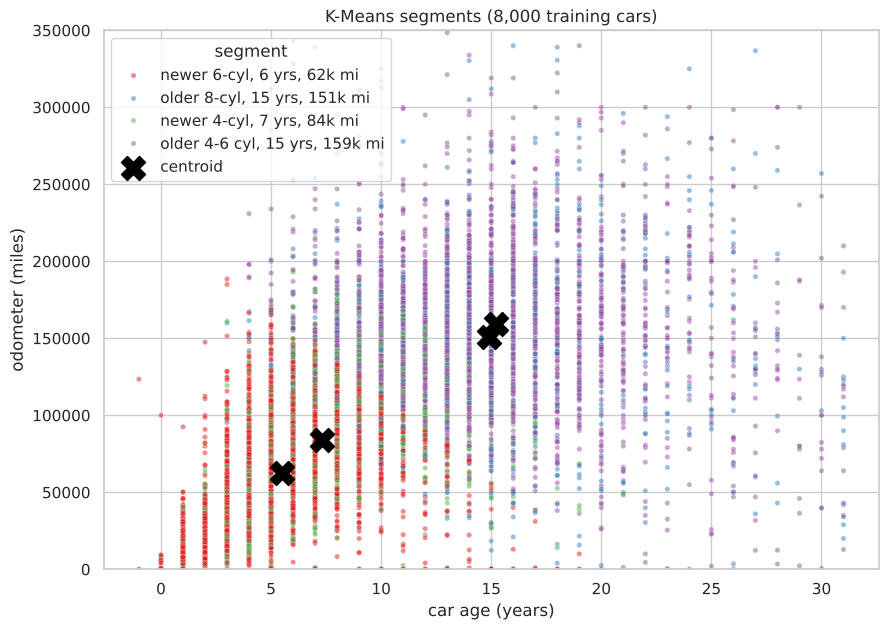

In [12]:
fig, ax = plt.subplots(figsize=(10, 7))
s = train.sample(8_000, random_state=RANDOM_STATE)
sns.scatterplot(data=s, x='car_age', y='odometer', hue=s['segment'].map(names), alpha=0.5, s=14, ax=ax,
                hue_order=[names[i] for i in order], palette='Set1')
ax.scatter(centroids['car_age'], centroids['odometer'], s=300, c='black', marker='X', label='centroid')
ax.set_title('K-Means segments (8,000 training cars)')
ax.set_xlabel('car age (years)')
ax.set_ylabel('odometer (miles)')
ax.set_ylim(0, 350_000)
ax.legend(title='segment', loc='upper left')
plt.show()

**The four segments (training cars):**

| Segment | Cars | Median price | Notes |
| --- | --- | --- | --- |
| Newer 6-cyl, 6 yrs, 62k mi | 60,296 | \$22,490 | 34% four-wheel drive |
| Newer 4-cyl, 7 yrs, 84k mi | 32,308 | \$10,750 | Commuter cars: 1.5% pickups |
| Older 8-cyl, 15 yrs, 151k mi | 20,319 | \$11,500 | 45% pickups or trucks, 54% four-wheel drive |
| Older 4–6 cyl, 15 yrs, 159k mi | 53,192 | \$5,980 | |

- **Old V8 trucks hold their value:** the same age and mileage as the last segment, but about twice the price.
- The segments overlap in the age-vs-mileage plot because **cylinders** separates them, the third feature, much as
  in the clustering lab, where each cluster stood out on a different feature.

**The pricing tool by segment (test cars):**

- It works best for **newer cars**: commuter 4-cylinders (median error 12.6%, 88.9% of prices inside the 80% range)
  and newer 6-cylinders (13.5%, 85.1%).
- It is weakest for the **two older segments** (median error 18.8–20.7%, only 71–73% inside the range). Old cars
  differ a lot in condition, which the data barely records.
- The dollar MAE is highest for newer 6-cylinders (\$4,717) only because those cars cost more.

## 3. Agglomerative clustering: groups of car makes

Each make is described by a profile built from the **training cars**: median price (log), median age, median
mileage, share of diesels, share of pickups and trucks, and median cylinders. Only makes with at least 200 training
cars are used, so each profile is stable. With about 30 rows, agglomerative clustering is instant and the full
dendrogram can be drawn, as in the lesson.

In [13]:
prof = train.groupby('manufacturer').agg(
    cars=('price', 'size'), median_price=('price', 'median'), median_age=('car_age', 'median'),
    median_miles=('odometer', 'median'),
    diesel_share=('fuel', lambda s: (s == 'diesel').mean()),
    truck_share=('type', lambda s: s.isin(['pickup', 'truck']).mean()),
    median_cyl=('cylinders_num', 'median'))
prof = prof[prof['cars'] >= 200]
prof_X = pd.DataFrame({'log_price': np.log(prof['median_price']), 'age': prof['median_age'],
                       'miles': prof['median_miles'], 'diesel': prof['diesel_share'],
                       'truck': prof['truck_share'], 'cyl': prof['median_cyl'].fillna(prof['median_cyl'].median())},
                      index=prof.index)
prof_scaled = StandardScaler().fit_transform(prof_X)
print(f'{len(prof)} makes with at least 200 training cars')

sil_k = {k: silhouette_score(prof_scaled, AgglomerativeClustering(n_clusters=k).fit_predict(prof_scaled))
         for k in range(2, 8)}
pd.Series(sil_k).round(3).rename('silhouette').to_frame().T

35 makes with at least 200 training cars


,2,3,4,5,6,7
silhouette,0.457,0.431,0.289,0.307,0.319,0.322


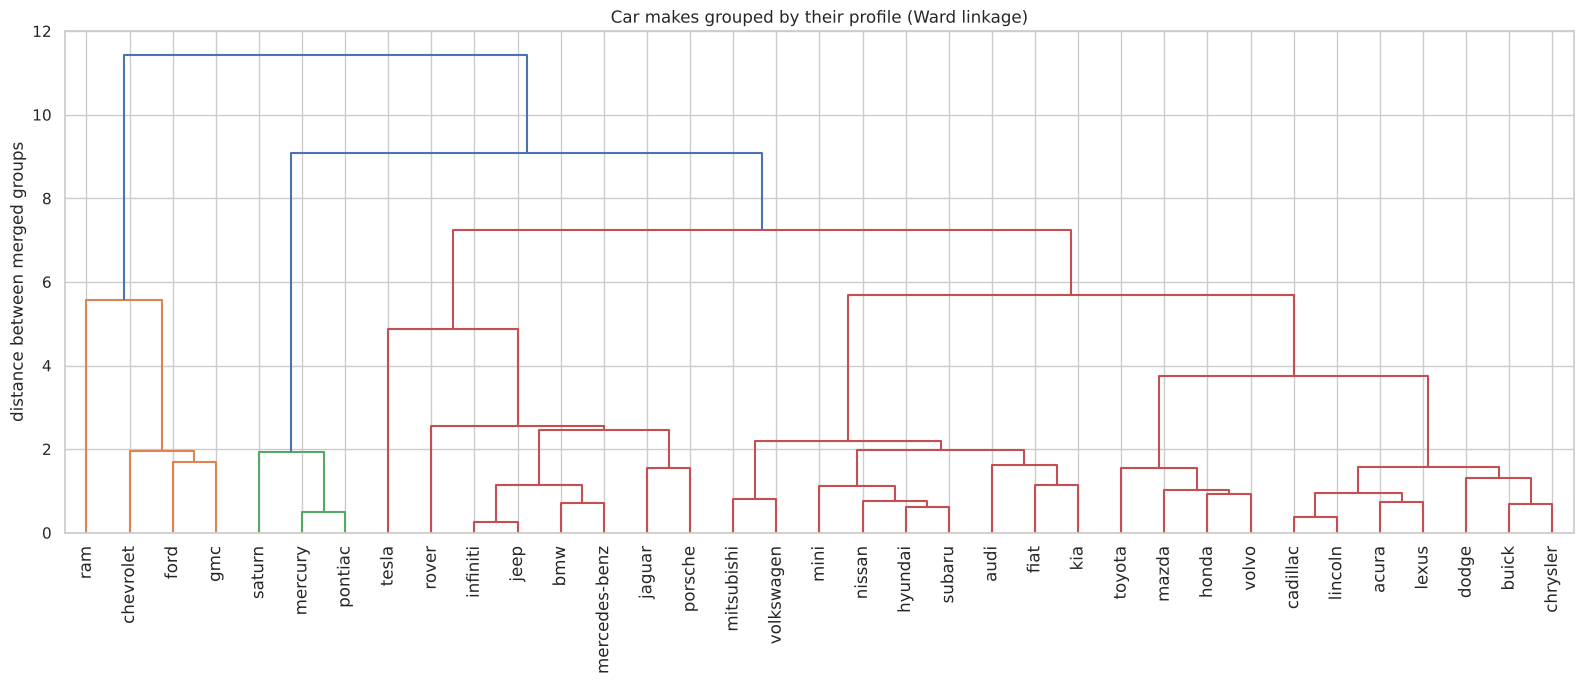

In [14]:
from scipy.cluster.hierarchy import dendrogram

# From the lesson (taken from the scikit-learn docs): build the linkage matrix and draw the dendrogram
def plot_dendrogram(model, **kwargs):
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            current_count += 1 if child_idx < n_samples else counts[child_idx - n_samples]
        counts[i] = current_count
    linkage_matrix = np.column_stack([model.children_, model.distances_, counts]).astype(float)
    dendrogram(linkage_matrix, **kwargs)

full_tree = AgglomerativeClustering(n_clusters=None, distance_threshold=0).fit(prof_scaled)
plt.figure(figsize=(16, 7))
plot_dendrogram(full_tree, labels=prof.index.tolist(), leaf_rotation=90, leaf_font_size=12)
plt.title('Car makes grouped by their profile (Ward linkage)')
plt.ylabel('distance between merged groups')
plt.tight_layout()
plt.show()

In [15]:
K_MAKE = max(sil_k, key=sil_k.get)
agg = AgglomerativeClustering(n_clusters=K_MAKE).fit(prof_scaled)
prof['make_group'] = agg.labels_
summary = prof.groupby('make_group').agg(makes=('cars', 'size'), cars=('cars', 'sum'),
                                         median_price=('median_price', 'median'),
                                         truck_share=('truck_share', 'mean'), diesel_share=('diesel_share', 'mean'),
                                         median_age=('median_age', 'median')).round(2)
summary['members'] = prof.groupby('make_group').apply(lambda d: ', '.join(d.index))
print(f'k = {K_MAKE} (highest silhouette, {sil_k[K_MAKE]:.3f})')
summary

k = 2 (highest silhouette, 0.457)


,makes,cars,median_price,truck_share,diesel_share,median_age,members
make_group,,,,,,,
0,31,100900,10000.0,0.01,0.01,9.0,"acura, audi, bmw, buick, cadillac, chrysler, d..."
1,4,59597,15247.5,0.42,0.16,9.0,"chevrolet, ford, gmc, ram"


**Make groups:**

- The silhouette score is highest at **k = 2 (0.457)**, then k = 3 (0.431), and much lower from k = 4.
- **k = 2 splits the four US truck brands (Chevrolet, Ford, GMC, Ram) from the 31 other makes.** The truck group
  has 42% pickups or trucks and 16% diesels, and a median price of \$15,248 against \$10,000.
- The dendrogram shows the next splits:
  - Saturn, Mercury and Pontiac, brands discontinued in 2010–2011 (old, cheap cars).
  - Inside the large branch, a **premium and SUV** branch (Tesla, Land Rover, Infiniti, Jeep, BMW, Mercedes-Benz,
    Jaguar, Porsche) and an **everyday** branch (Toyota, Honda, Nissan, Hyundai and the rest).

## 4. Do the clusters help the price model?

The make group and the K-Means segment can be added to the Random Forest as two more categorical features.
Both come from models fit on the training cars; test cars are only labelled by them, so nothing from the test set
leaks in. Makes with fewer than 200 training cars get their own `small make` level.

In [16]:
def with_clusters(X):
    X = X.copy()
    X['make_group'] = X['manufacturer'].map(prof['make_group']).map(lambda g: f'group {int(g)}' if pd.notna(g) else 'small make')
    X['segment'] = kmeans.predict(seg_scaler.transform(X[seg_cols].fillna(seg_median))).astype(str)
    return X

Xtr_c, Xte_c = with_clusters(X_train), with_clusters(X_test)
t = time.time()
p_make = rf_predict(Xtr_c, y_train, Xte_c, extra_cats=['make_group'])
p_both = rf_predict(Xtr_c, y_train, Xte_c, extra_cats=['make_group', 'segment'])
print(f'two fits: {time.time() - t:.0f} s')
cluster_table = pd.DataFrame([
    scores('Random Forest (as before)', y_test.values, p_base),
    scores('+ make group', y_test.values, p_make),
    scores('+ make group + segment', y_test.values, p_both),
]).set_index('model').round(1)
cluster_table

two fits: 139 s


,MAE,MAE under $5k,median % error
model,,,
Random Forest (as before),3231.4,1785.9,15.8
+ make group,3199.6,1778.2,15.5
+ make group + segment,3210.4,1780.1,15.6


**A small gain from the make group:**

- Adding the make group lowers the MAE from \$3,231 to **\$3,200** (\$32, 1.0%) and the median % error from 15.8% to
  15.5%.
- Adding the segment as well undoes part of the gain (\$3,210). The segment is a rough summary of age, mileage and
  cylinders, which the forest already has.
- The whole gain comes from one feature saying "this is a Chevrolet, Ford, GMC or Ram". It is real but small, about
  the size of the gap between Random Forest and Gradient Boosting on new listings (\$22). Adding it to the main model
  would mean re-tuning and re-running notebooks 05–07, so it is logged as a candidate in `docs/04` instead.

In [17]:
# Save the cluster results for the README and later notebooks
out = by_seg.reset_index().rename(columns={'segment_name': 'segment'})
out.to_csv('../results/segments.csv', index=False)
prof[['cars', 'median_price', 'make_group']].reset_index().to_csv('../results/make_groups.csv', index=False)
pd.concat([rule_table, cluster_table]).to_csv('../results/clustering_checks.csv')
print('saved: results/segments.csv, results/make_groups.csv, results/clustering_checks.csv')

saved: results/segments.csv, results/make_groups.csv, results/clustering_checks.csv


## Summary

| Lesson | Used for | Result |
| --- | --- | --- |
| DBSCAN | Spot unusual ads (5% of a 30,000-car sample) | Catches 100% of odometer-typo cars, 63% of cars over 25 years, ~30% of extreme prices |
| DBSCAN → fixed rule | Fix odometer typos before modelling | No gain (MAE \$3,231 both ways); worse on the cars it changes, so not adopted |
| K-Means (k = 4) | Describe car segments | Pricing tool is best for newer cars (85–89% inside the range), weakest for older cars (71–73%) |
| Agglomerative + dendrogram | Group 35 makes | Best split: US truck brands vs the rest; as a feature, MAE \$3,231 → \$3,200 (−1%) |

- **Clustering explains the data more than it improves the model.** The Random Forest already finds these patterns
  from the raw columns.
- **Its practical value is for the pricing tool:** flag DBSCAN-noise ads for a second look, and show buyers that
  ranges for older cars are less reliable.

Saved: `results/segments.csv`, `results/make_groups.csv`, `results/clustering_checks.csv`.